In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

fileName = "LA_AQS_2023.csv"

df = pd.read_csv(fileName)
df["Date (Local)"] = pd.to_datetime(df["Date (Local)"])

In [66]:
df_O3 = df[(df['Parameter Name']=='Ozone') & (df['Duration Description']=='1 HOUR')].copy()
df_O3["O3"] = df_O3["Arithmetic Mean"]*1000


df_NO2 = df[(df['Parameter Name']=='Nitrogen dioxide (NO2)') & (df['Duration Description']=='1 HOUR')].copy()
df_NO2 = df_NO2.groupby("Date (Local)", as_index=False)["Arithmetic Mean"].mean()
df_NO2["NO2"] = df_NO2["Arithmetic Mean"]

df_PM25 = df[(df['Parameter Name']=='PM2.5 - Local Conditions') & (df['Duration Description']=='1 HOUR')].copy()
df_PM25 = df_PM25.groupby("Date (Local)", as_index=False)["Arithmetic Mean"].mean()
df_PM25["PM25"] = df_PM25["Arithmetic Mean"]

In [67]:
df_all = df_O3[["Date (Local)", "O3"]].merge(df_NO2[["Date (Local)", "NO2"]], on="Date (Local)")

df_all = df_all.merge(df_PM25[["Date (Local)", "PM25"]], on="Date (Local)").dropna()

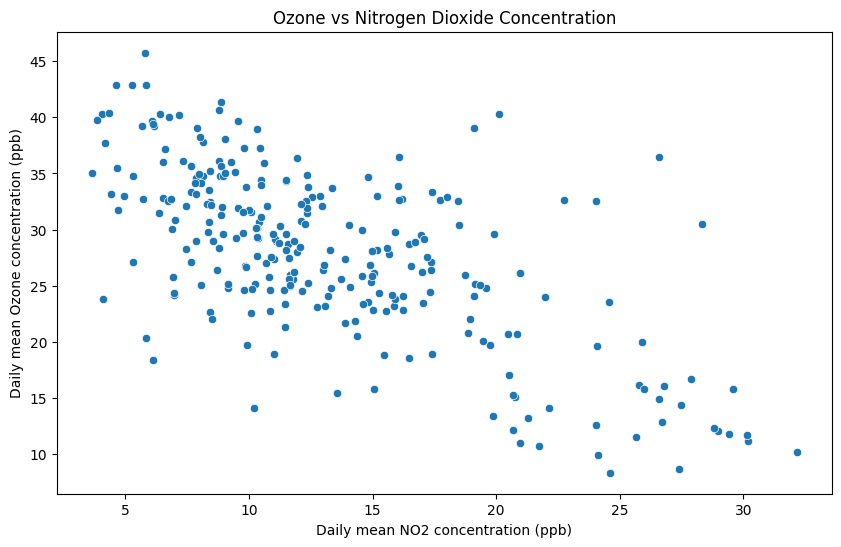

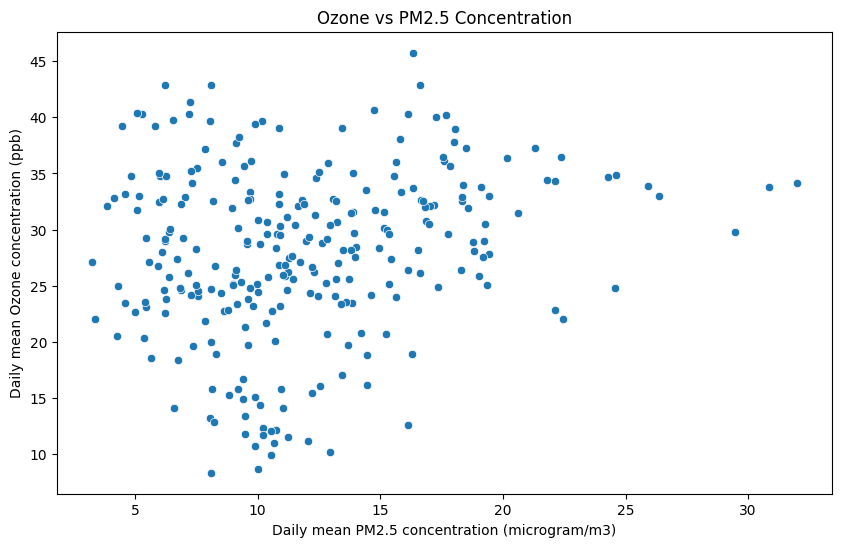

In [68]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_all, x="NO2", y="O3")
plt.title("Ozone vs Nitrogen Dioxide Concentration")
plt.xlabel("Daily mean NO2 concentration (ppb)")
plt.ylabel("Daily mean Ozone concentration (ppb)")
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_all, x="PM25", y="O3")
plt.title("Ozone vs PM2.5 Concentration")
plt.xlabel("Daily mean PM2.5 concentration (microgram/m3)")
plt.ylabel("Daily mean Ozone concentration (ppb)")
plt.show()

In [69]:
df_all["Month"] = df_all["Date (Local)"].dt.month
df_all = df_all[df_all["Month"].isin([12, 1, 2, 6, 7, 8])].copy()
df_all["Season"] = np.where(df_all["Month"].isin([6, 7, 8]), "Summer", "Winter")

In [70]:
X = df_all[["O3", "NO2", "PM25"]].values
y = np.where(df_all["Season"]=="Summer", 1, -1)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=20)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

reg = linear_model.RidgeClassifier(alpha=1)
reg.fit(X_train, y_train)

print("Training error:", 1 - reg.score(X_train, y_train))
print("Validation error:", 1 - reg.score(X_val, y_val))

Training error: 0.14166666666666672
Validation error: 0.12903225806451613


In [71]:
alphas = np.arange(0, 1000, 0.1)
best_train_alpha = None
best_val_alpha = None
min_train_error = 100.0
min_val_error = 100.0

for alpha in alphas:
    reg = linear_model.RidgeClassifier(alpha=alpha)
    reg.fit(X_train, y_train)

    train_error = 1 - reg.score(X_train, y_train)
    val_error = 1 - reg.score(X_val, y_val)

    if train_error < min_train_error:
        min_train_error = train_error
        best_train_alpha = alpha

    if val_error < min_val_error:
        min_val_error = val_error
        best_val_alpha = alpha

print("Best training alpha:", best_train_alpha)
print("Minimum training error:", min_train_error)
print("Best validation alpha:", best_val_alpha)
print("Minimum validation error:", min_val_error)

Best training alpha: 0.0
Minimum training error: 0.1333333333333333
Best validation alpha: 335.3
Minimum validation error: 0.09677419354838712


In [72]:
reg = linear_model.RidgeClassifier(alpha=best_val_alpha)
reg.fit(X_train, y_train)

print("Validation error:", 1 - reg.score(X_val, y_val))

Validation error: 0.09677419354838712


In [73]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=50)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

best_train_alpha = None
best_val_alpha = None
min_train_error = 100.0
min_val_error = 100.0

for alpha in alphas:
    reg = linear_model.RidgeClassifier(alpha=alpha)
    reg.fit(X_train, y_train)

    train_error = 1 - reg.score(X_train, y_train)
    val_error = 1 - reg.score(X_val, y_val)

    if train_error < min_train_error:
        min_train_error = train_error
        best_train_alpha = alpha

    if val_error < min_val_error:
        min_val_error = val_error
        best_val_alpha = alpha

print("Best training alpha:", best_train_alpha)
print("Minimum training error:", min_train_error)
print("Best validation alpha:", best_val_alpha)
print("Minimum validation error:", min_val_error)

Best training alpha: 0.0
Minimum training error: 0.15000000000000002
Best validation alpha: 1.3
Minimum validation error: 0.09677419354838712


In [74]:
reg = linear_model.RidgeClassifier(alpha=best_val_alpha)
reg.fit(X_train, y_train)
print("Ridge validation error:", 1 - reg.score(X_val, y_val))

logreg = linear_model.LogisticRegression()
logreg.fit(X_train, y_train)
print("Logistic validation error:", 1 - logreg.score(X_val, y_val))

Ridge validation error: 0.09677419354838712
Logistic validation error: 0.09677419354838712
